# Exploratory Data Analysis — Ames Housing Dataset

**Objective**: Establish a rigorous statistical baseline for every modelling and preprocessing decision downstream. This notebook is a formal analytical deliverable — its conclusions are encoded as the `EDA_CFG` dictionary and referenced verbatim in `02_preprocessing.ipynb`.

**Scope**:
1. Data loading and structural audit
2. Target variable distribution and transformation rationale
3. Missing value taxonomy and imputation strategy
4. Numeric feature correlations and multicollinearity audit
5. Categorical feature cardinality and ordinal encoding decisions
6. Outlier identification and removal audit trail
7. Feature engineering candidates with empirical validation
8. Consolidated decisions log


## 1. Data Loading and Structural Audit

The dataset is loaded once into `df` and treated as immutable throughout EDA — all mutations operate on copies. The `EDA_CFG` dictionary is the **single source of truth** for all column-level decisions; downstream notebooks consume the same keys rather than re-deriving them independently, which would introduce config drift.

**Key `EDA_CFG` decisions encoded here:**

| Key | Value | Decision rationale |
|-----|-------|--------------------|
| `drop_cols` | `["Id", "Utilities"]` | `Id` is a row identifier with no predictive signal. `Utilities` is near-zero variance (>99% "AllPub") — it contributes noise, not signal, and would create a spurious dummy column post-encoding. |
| `outlier_indices` | `[523, 1298]` | Two domain-confirmed anomalies identified in Section 6. Catalogued here so preprocessing removes them before any data split. |
| `quality_cols` / `quality_order` | See config | Ordinal encoding contract — identical lists are referenced in `PREP_CFG` in `02_preprocessing.ipynb`. Divergence between the two configs produces silent encoding errors at inference time. |

This cell also sets global plot styling (`seaborn whitegrid`) and `pd.set_option("display.max_columns", 85)` to ensure consistent visualisation across all sections.


In [33]:
from pathlib import Path
import datetime
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# ---- EDA Config: single source of truth for all downstream decisions ----
# In production ML, this dict becomes a YAML/JSON config loaded at runtime.
EDA_CFG = {
    "data_path": Path("../data/ames_housing.csv"),
    "target": "SalePrice",
    "drop_cols": ["Id", "Utilities"],           # identifier + near-zero-variance
    "log_transform_target": True,
    "outlier_indices": [523, 1298],
    "fill_none_cols": [
        "PoolQC", "MiscFeature", "Alley", "Fence", "FireplaceQu",
        "GarageType", "GarageFinish", "GarageQual", "GarageCond",
        "BsmtQual", "BsmtCond", "BsmtExposure", "BsmtFinType1", "BsmtFinType2",
        "MasVnrType",
    ],
    "fill_zero_cols": [
        "MasVnrArea", "GarageYrBlt", "GarageArea", "GarageCars",
        "BsmtFinSF1", "BsmtFinSF2", "BsmtUnfSF", "TotalBsmtSF",
    ],
    # Genuinely missing categoricals — mode fill
    "fill_mode_cols": ["Electrical", "MSZoning", "Exterior1st", "Exterior2nd", "SaleType"],
    # Group-wise imputation: {column: groupby_column}
    "fill_median_group_cols": {"LotFrontage": "Neighborhood"},
    # Ordinal quality features and their ranked category order (low → high)
    "quality_order": ["Po", "Fa", "TA", "Gd", "Ex"],
    "quality_cols": [
        "ExterQual", "ExterCond", "BsmtQual", "BsmtCond",
        "HeatingQC", "KitchenQual", "FireplaceQu", "GarageQual", "GarageCond",
    ],
}

sns.set_style("whitegrid")
pd.set_option("display.max_columns", 85)
print("Packages loaded. EDA_CFG initialised.")

Packages loaded. EDA_CFG initialised.


In [34]:
df = pd.read_csv(EDA_CFG["data_path"])
df = df.drop(columns=EDA_CFG["drop_cols"], errors="ignore")

n_rows, n_cols = df.shape
n_numeric  = df.select_dtypes(include="number").shape[1]
n_cat      = df.select_dtypes(include="object").shape[1]

print(f"Shape       : {n_rows:,} rows × {n_cols} columns")
print(f"Numeric     : {n_numeric}")
print(f"Categorical : {n_cat}")
print(f"Duplicates  : {df.duplicated().sum()}")
df.head()

Shape       : 1,460 rows × 79 columns
Numeric     : 37
Categorical : 42
Duplicates  : 0


/tmp/ipykernel_1930252/868475882.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  n_cat      = df.select_dtypes(include="object").shape[1]


,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,LotConfig,LandSlope,Neighborhood,Condition1,Condition2,BldgType,HouseStyle,OverallQual,OverallCond,YearBuilt,YearRemodAdd,RoofStyle,RoofMatl,Exterior1st,Exterior2nd,MasVnrType,MasVnrArea,ExterQual,ExterCond,Foundation,BsmtQual,BsmtCond,BsmtExposure,BsmtFinType1,BsmtFinSF1,BsmtFinType2,BsmtFinSF2,BsmtUnfSF,TotalBsmtSF,Heating,HeatingQC,CentralAir,Electrical,1stFlrSF,2ndFlrSF,LowQualFinSF,GrLivArea,BsmtFullBath,BsmtHalfBath,FullBath,HalfBath,BedroomAbvGr,KitchenAbvGr,KitchenQual,TotRmsAbvGrd,Functional,Fireplaces,FireplaceQu,GarageType,GarageYrBlt,GarageFinish,GarageCars,GarageArea,GarageQual,GarageCond,PavedDrive,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2003,2003,Gable,CompShg,VinylSd,VinylSd,BrkFace,196.0,Gd,TA,PConc,Gd,TA,No,GLQ,706,Unf,0,150,856,GasA,Ex,Y,SBrkr,856,854,0,1710,1,0,2,1,3,1,Gd,8,Typ,0,NaN,Attchd,2003.0,RFn,2,548,TA,TA,Y,0,61,0,0,0,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,FR2,Gtl,Veenker,Feedr,Norm,1Fam,1Story,6,8,1976,1976,Gable,CompShg,MetalSd,MetalSd,NaN,0.0,TA,TA,CBlock,Gd,TA,Gd,ALQ,978,Unf,0,284,1262,GasA,Ex,Y,SBrkr,1262,0,0,1262,0,1,2,0,3,1,TA,6,Typ,1,TA,Attchd,1976.0,RFn,2,460,TA,TA,Y,298,0,0,0,0,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,Inside,Gtl,CollgCr,Norm,Norm,1Fam,2Story,7,5,2001,2002,Gable,CompShg,VinylSd,VinylSd,BrkFace,162.0,Gd,TA,PConc,Gd,TA,Mn,GLQ,486,Unf,0,434,920,GasA,Ex,Y,SBrkr,920,866,0,1786,1,0,2,1,3,1,Gd,6,Typ,1,TA,Attchd,2001.0,RFn,2,608,TA,TA,Y,0,42,0,0,0,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,Corner,Gtl,Crawfor,Norm,Norm,1Fam,2Story,7,5,1915,1970,Gable,CompShg,'Wd Sdng','Wd Shng',NaN,0.0,TA,TA,BrkTil,TA,Gd,No,ALQ,216,Unf,0,540,756,GasA,Gd,Y,SBrkr,961,756,0,1717,1,0,1,0,3,1,Gd,7,Typ,1,Gd,Detchd,1998.0,Unf,3,642,TA,TA,Y,0,35,272,0,0,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,FR2,Gtl,NoRidge,Norm,Norm,1Fam,2Story,8,5,2000,2000,Gable,CompShg,VinylSd,VinylSd,BrkFace,350.0,Gd,TA,PConc,Gd,TA,Av,GLQ,655,Unf,0,490,1145,GasA,Ex,Y,SBrkr,1145,1053,0,2198,1,0,2,1,4,1,Gd,9,Typ,1,TA,Attchd,2000.0,RFn,3,836,TA,TA,Y,192,84,0,0,0,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


## 2. Target Variable Analysis — SalePrice

SalePrice follows a strongly right-skewed log-normal distribution (skewness ≈ 1.88). Training a regression model directly on a skewed target has two concrete consequences:

1. **Loss function bias**: MSE/RMSE penalises large prediction errors quadratically. On a skewed target a handful of $500K+ homes dominate the gradient signal at the cost of precision on the majority of $100K–$250K transactions.
2. **Violated residual assumptions**: Linear model diagnostics (prediction intervals, homoscedasticity tests) assume normally distributed residuals. A log-normal target produces heteroscedastic residuals that widen as price increases — exactly what the residual analysis in `03_modelling.ipynb` will surface.

**Decision: train on `log1p(SalePrice)`.**

`np.log1p(x)` computes $\ln(x + 1)$, which:
- Compresses the upper tail into a near-normal distribution
- Handles the theoretical edge case `SalePrice = 0` without a domain error (no such cases exist here, but the `+1` guard is production-safe)
- Produces a symmetric Q-Q plot against a normal reference line

All metrics are computed on the log scale during training. Dollar-denominated reporting to stakeholders uses `np.expm1(y_pred)` to invert the transform — this is implemented in the `evaluate()` helper in `03_modelling.ipynb`.


Statistic       Raw             Log-Transformed
---------------------------------------------
  mean          180921.1959     12.0241
  median        163000.0000     12.0015
  std           79442.5029      0.3994
  skewness      1.8829          0.1213
  kurt(exc)     6.5363          0.8095


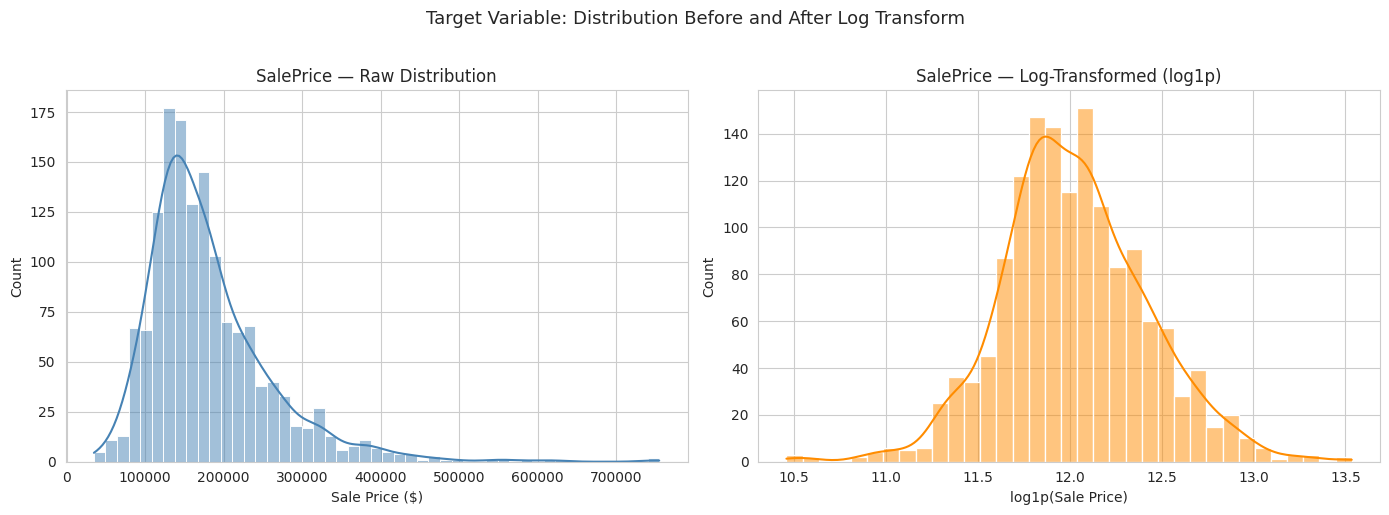

In [35]:
target = EDA_CFG["target"]

print(f"{'Statistic':<15} {'Raw':<15} {'Log-Transformed'}")
print("-" * 45)
for stat, raw_val, log_val in [
    ("mean",     df[target].mean(),              np.log1p(df[target]).mean()),
    ("median",   df[target].median(),            np.log1p(df[target]).median()),
    ("std",      df[target].std(),               np.log1p(df[target]).std()),
    ("skewness", df[target].skew(),              np.log1p(df[target]).skew()),
    # pandas kurtosis() returns Fischer's excess kurtosis (normal = 0)
    ("kurt(exc)",df[target].kurtosis(),          np.log1p(df[target]).kurtosis()),
]:
    print(f"  {stat:<13} {raw_val:<15.4f} {log_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df[target], ax=axes[0], kde=True, color="steelblue")
axes[0].set_title("SalePrice — Raw Distribution")
axes[0].set_xlabel("Sale Price ($)")
axes[0].set_ylabel("Count")

sns.histplot(np.log1p(df[target]), ax=axes[1], kde=True, color="darkorange")
axes[1].set_title("SalePrice — Log-Transformed (log1p)")
axes[1].set_xlabel("log1p(Sale Price)")
axes[1].set_ylabel("Count")

plt.suptitle("Target Variable: Distribution Before and After Log Transform", y=1.02, fontsize=13)
plt.tight_layout()
plt.show()

## 3. Missing Value Taxonomy and Imputation Strategy

Nineteen columns contain missing values. The critical analytical step is distinguishing between **structural absences** and **true data gaps** — treating them uniformly (e.g., median-filling everything) is a modelling error that misrepresents the underlying data-generating process.

**Imputation taxonomy:**

| Strategy | Columns | Domain rationale |
|----------|---------|-----------------|
| `"None"` (string sentinel) | `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, all `Garage*` quality/type/finish, all `Bsmt*` quality/exposure/fin-type, `MasVnrType` | NaN encodes structural absence — the property has no pool, no alley, no garage. The string sentinel `"None"` (not `np.nan`) is used so downstream ordinal encoding maps it unambiguously to `0`. |
| `0` (numeric zero) | `MasVnrArea`, `GarageYrBlt`, `GarageArea`, `GarageCars`, all `BsmtFinSF*`, `TotalBsmtSF` | NaN encodes a zero-quantity measurement — no garage means zero garage area. |
| Mode fill | `Electrical`, `MSZoning`, `Exterior1st`, `Exterior2nd`, `SaleType` | True data gaps with very low missing rates (<1%). Mode fill introduces minimal bias at this scale. |
| Group-wise median | `LotFrontage` (grouped by `Neighborhood`) | Lot frontage is partially predictable by neighbourhood street layout. A global median ignores this spatial signal; the group-wise imputation implemented via `groupby().transform("median")` preserves it. |

This taxonomy is encoded in `EDA_CFG` and reproduced exactly in `PREP_CFG` in `02_preprocessing.ipynb`. The code below validates that every column with missing values has a strategy assigned — any `UNASSIGNED` result is a config gap that must be resolved before preprocessing runs.


All 19 missing-value columns covered by EDA_CFG.

              count        pct      strategy
PoolQC         1453  99.520548     fill_none
MiscFeature    1406  96.301370     fill_none
Alley          1369  93.767123     fill_none
Fence          1179  80.753425     fill_none
MasVnrType      872  59.726027     fill_none
FireplaceQu     690  47.260274     fill_none
LotFrontage     259  17.739726  group_median
GarageType       81   5.547945     fill_none
GarageYrBlt      81   5.547945     fill_zero
GarageFinish     81   5.547945     fill_none
GarageQual       81   5.547945     fill_none
GarageCond       81   5.547945     fill_none
BsmtExposure     38   2.602740     fill_none
BsmtFinType2     38   2.602740     fill_none
BsmtQual         37   2.534247     fill_none
BsmtCond         37   2.534247     fill_none
BsmtFinType1     37   2.534247     fill_none
MasVnrArea        8   0.547945     fill_zero
Electrical        1   0.068493     fill_mode


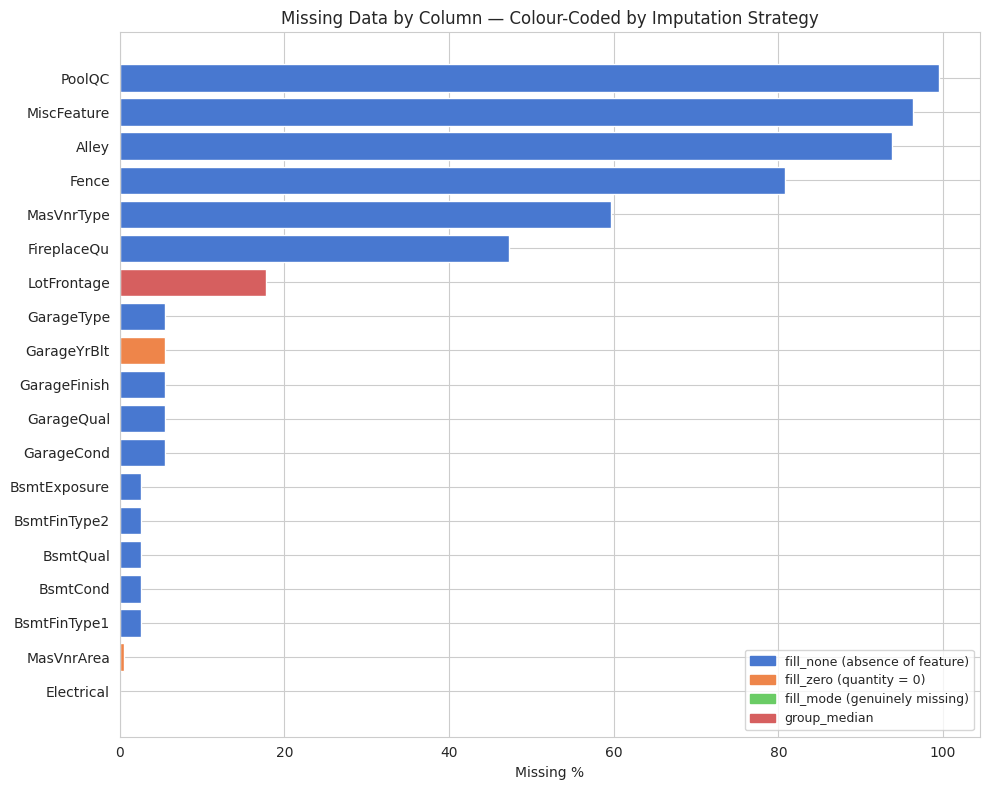

In [36]:
# --- Read imputation lists directly from EDA_CFG (do NOT redefine them) ---
all_imputed_cols = (
    EDA_CFG["fill_none_cols"]
    + EDA_CFG["fill_zero_cols"]
    + EDA_CFG["fill_mode_cols"]
    + list(EDA_CFG["fill_median_group_cols"].keys())
)

missing_count = df.isnull().sum()
missing_pct   = missing_count / len(df) * 100
missing_df    = (
    pd.DataFrame({"count": missing_count, "pct": missing_pct})
    .query("count > 0")
    .sort_values("pct", ascending=False)
    .assign(strategy=lambda x: x.index.map(
        lambda c: (
            "fill_none"        if c in EDA_CFG["fill_none_cols"]        else
            "fill_zero"        if c in EDA_CFG["fill_zero_cols"]        else
            "fill_mode"        if c in EDA_CFG["fill_mode_cols"]        else
            "group_median"     if c in EDA_CFG["fill_median_group_cols"] else
            "UNASSIGNED"
        )
    ))
)

# Verify every missing column has a strategy — fail fast if any are unassigned
unassigned = missing_df[missing_df["strategy"] == "UNASSIGNED"]
if not unassigned.empty:
    print(f"WARNING: {len(unassigned)} column(s) have no imputation strategy: {unassigned.index.tolist()}")
else:
    print(f"All {len(missing_df)} missing-value columns covered by EDA_CFG.\n")

print(missing_df.to_string())

# Horizontal bar chart — more readable with many column names
fig, ax = plt.subplots(figsize=(10, 8))
colors  = missing_df["strategy"].map({
    "fill_none":    "#4878d0",
    "fill_zero":    "#ee854a",
    "fill_mode":    "#6acc65",
    "group_median": "#d65f5f",
    "UNASSIGNED":   "#888888",
})
ax.barh(missing_df.index, missing_df["pct"], color=colors)
ax.set_xlabel("Missing %")
ax.set_title("Missing Data by Column — Colour-Coded by Imputation Strategy")
ax.invert_yaxis()   # highest at top
# Add a legend
from matplotlib.patches import Patch
legend_elements = [
    Patch(color="#4878d0", label="fill_none (absence of feature)"),
    Patch(color="#ee854a", label="fill_zero (quantity = 0)"),
    Patch(color="#6acc65", label="fill_mode (genuinely missing)"),
    Patch(color="#d65f5f", label="group_median"),
]
ax.legend(handles=legend_elements, loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

## 4. Numeric Feature Correlations and Multicollinearity Audit

Pearson correlation against `SalePrice` provides a first-pass feature ranking. Two supplementary analyses are required to avoid misinterpreting it:

**1. Correlation magnitude underestimates non-linear relationships.** `OverallQual` (ordinal 1–10) has the highest correlation (r ≈ 0.79), partly because it acts as a proxy for many other quality signals — its true predictive contribution in a tree-based model will be even higher than linear correlation suggests.

**2. Multicollinear feature pairs inflate coefficient variance** in unregularised models (OLS) and split importance across correlated siblings in tree models. Key pairs to note for model interpretation:

| Pair | r | Implication |
|------|---|-------------|
| `GarageArea` / `GarageCars` | ≈ 0.88 | Two measurements of the same garage — keep both for now; Ridge L2 shrinkage handles the redundancy. |
| `TotalBsmtSF` / `1stFlrSF` | ≈ 0.82 | Single-storey houses have near-identical values for both; engineered `TotalSF` absorbs both. |
| `GrLivArea` / `TotRmsAbvGrd` | ≈ 0.83 | Room count is a near-linear proxy for living area; XGBoost feature importance will be split between them. |

The heatmap is curated to the top 15 features by `|r|` with SalePrice. A full 38×38 matrix is analytically useless — the signal is buried. Curating the visualisation is not cosmetic; it is a communication decision.


In [37]:
numeric_df = df.select_dtypes(include=[np.number])
corr_matrix = numeric_df.corr()

# full_corr: complete ranking — do NOT truncate here; reused in heatmap cell below
full_corr = corr_matrix["SalePrice"].drop("SalePrice").abs().sort_values(ascending=False)
top_corr  = full_corr.head(10)

print("Top 10 features correlated with SalePrice:\n")
print(top_corr.to_string())

# Multicollinear pairs — exclude SalePrice so we only scan X-feature pairs
feature_cols = [c for c in corr_matrix.columns if c != "SalePrice"]
colinear_pairs = []
for i in range(len(feature_cols)):
    for j in range(i + 1, len(feature_cols)):
        r = corr_matrix.loc[feature_cols[i], feature_cols[j]]
        if abs(r) > 0.7:
            colinear_pairs.append((feature_cols[i], feature_cols[j], round(float(r), 4)))

colinear_pairs.sort(key=lambda x: abs(x[2]), reverse=True)
print(f"\nMulticollinear X-feature pairs (|r| > 0.7): {len(colinear_pairs)} found")
for a, b, r in colinear_pairs:
    print(f"  {a:<28} ~ {b:<28}  r = {r:+.4f}")

Top 10 features correlated with SalePrice:

OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101

Multicollinear X-feature pairs (|r| > 0.7): 4 found
  GarageCars                   ~ GarageArea                    r = +0.8825
  YearBuilt                    ~ GarageYrBlt                   r = +0.8257
  GrLivArea                    ~ TotRmsAbvGrd                  r = +0.8255
  TotalBsmtSF                  ~ 1stFlrSF                      r = +0.8195


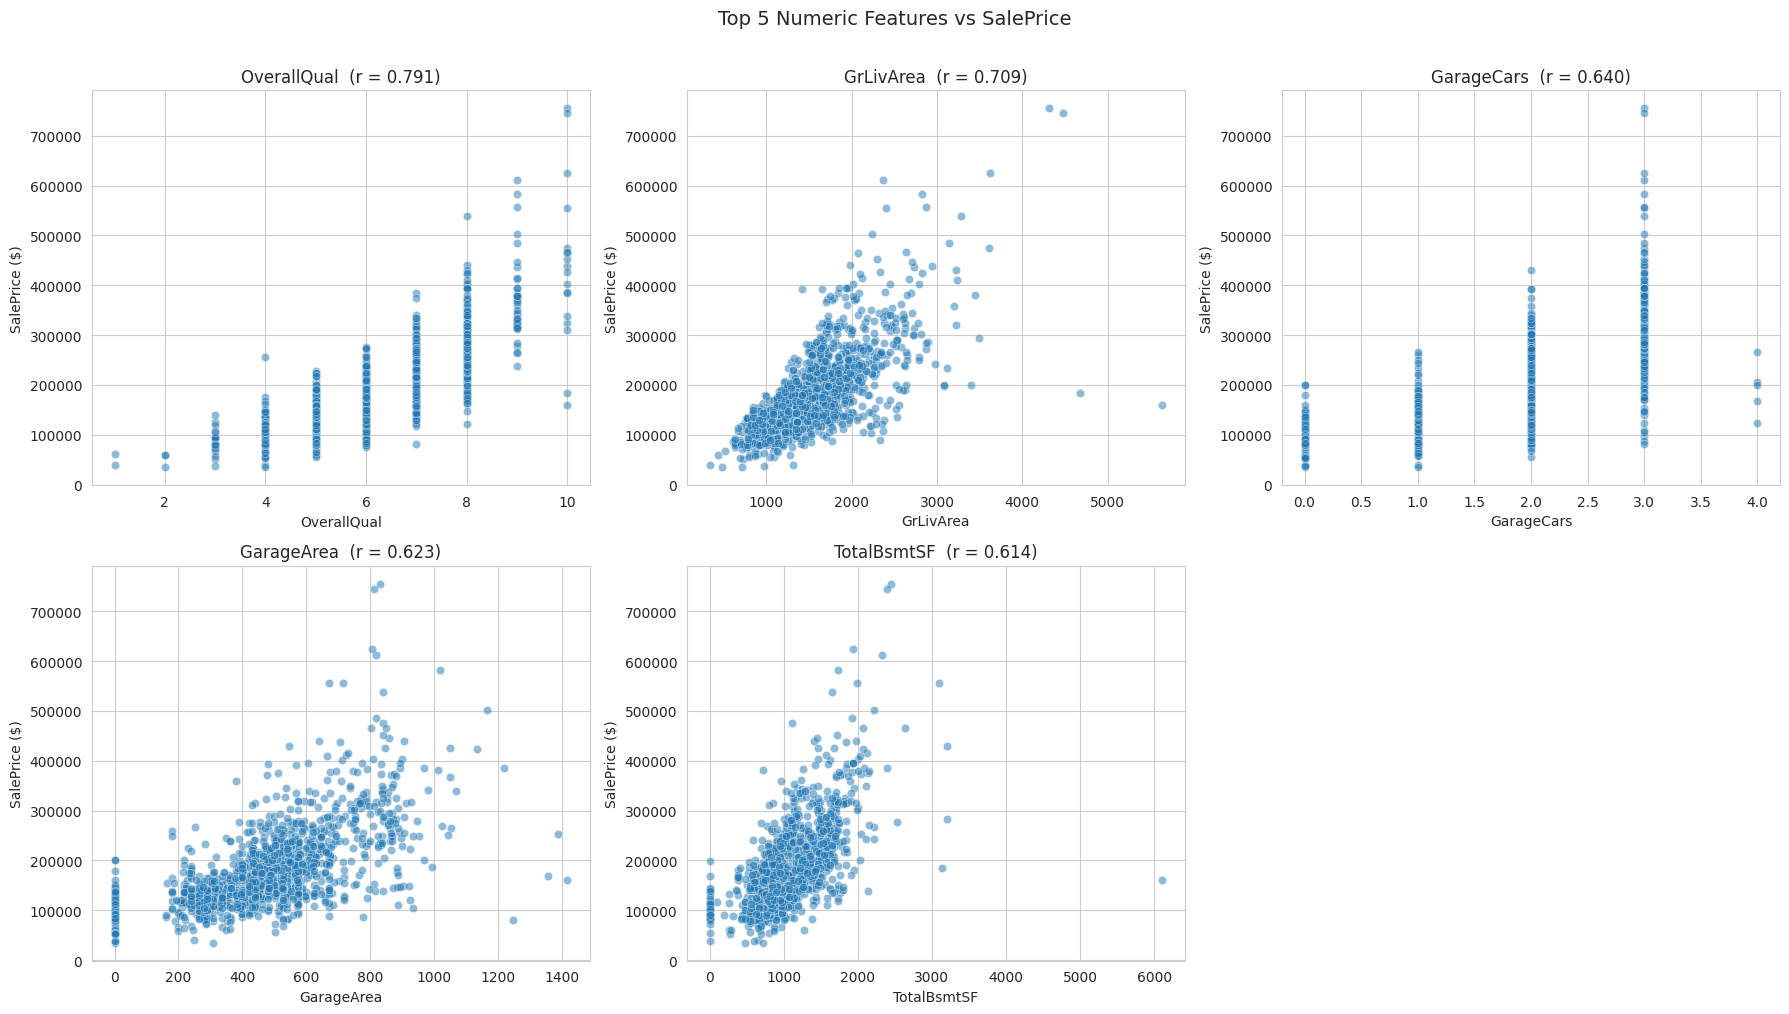

In [38]:
# Plot top 5 features — index [:5], NOT [1:6] which incorrectly skips OverallQual
top5_features = top_corr.index[:5]

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, feature in enumerate(top5_features):
    row, col = divmod(i, 3)
    sns.scatterplot(x=df[feature], y=df[EDA_CFG["target"]], ax=axes[row, col], alpha=0.5)
    r_val = full_corr[feature]
    axes[row, col].set_title(f"{feature}  (r = {r_val:.3f})")
    axes[row, col].set_xlabel(feature)
    axes[row, col].set_ylabel("SalePrice ($)")

axes[1, 2].set_visible(False)   # hide the empty 6th subplot

plt.suptitle("Top 5 Numeric Features vs SalePrice", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

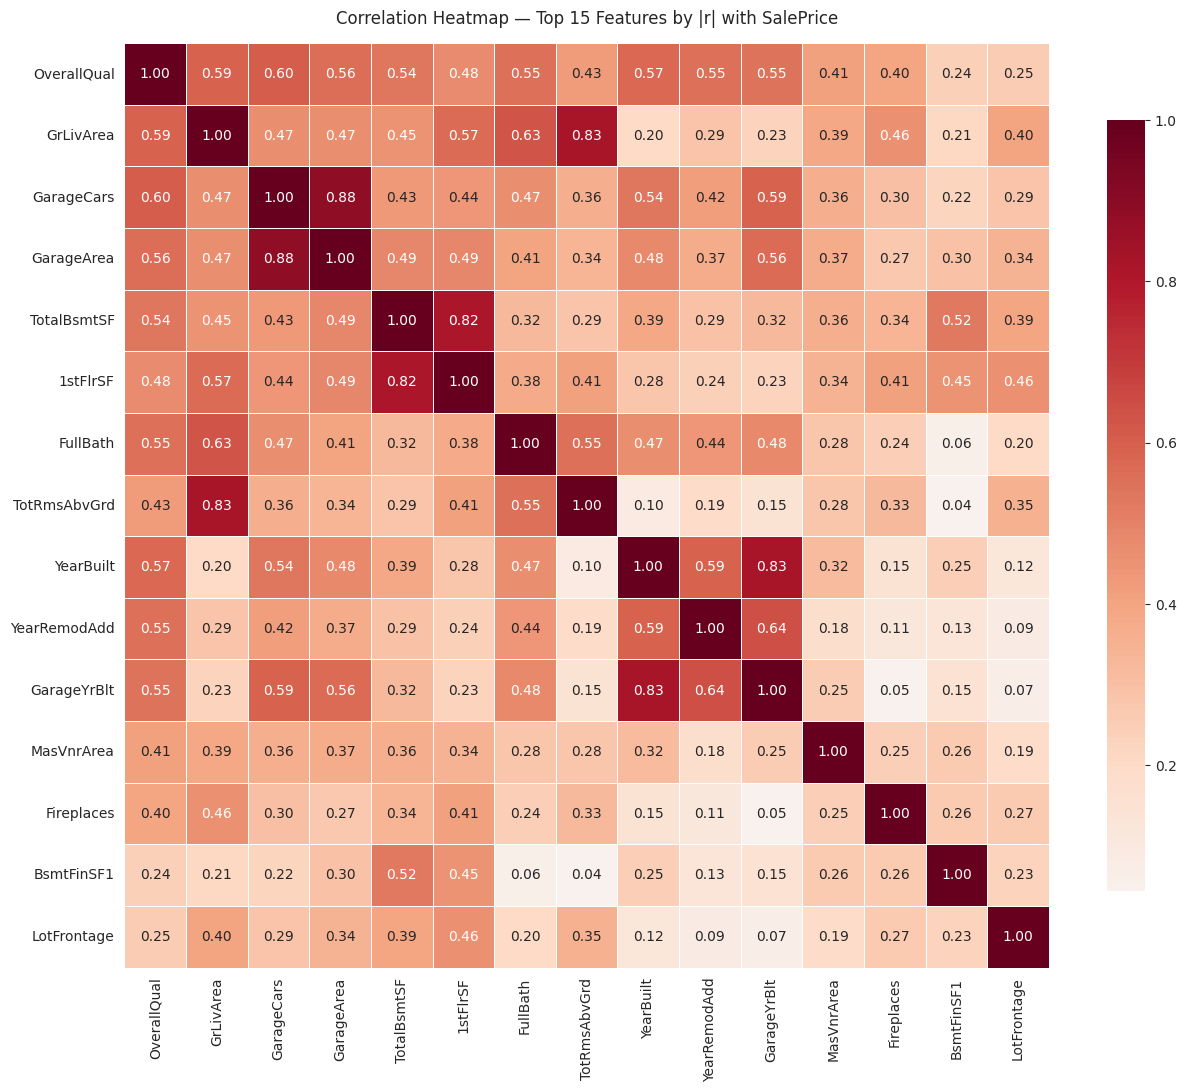

In [39]:
# Use full_corr (not the truncated top_corr) to get the genuine top 15
top_15_features   = full_corr.head(15).index
top_15_corr_matrix = corr_matrix.loc[top_15_features, top_15_features]

plt.figure(figsize=(13, 11))
sns.heatmap(
    top_15_corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.8},
)
plt.title("Correlation Heatmap — Top 15 Features by |r| with SalePrice", pad=14)
plt.tight_layout()
plt.show()

## 5. Categorical Feature Analysis

**Cardinality and encoding decisions:**

| Feature | Unique values | Encoding decision | Rationale |
|---------|--------------|-------------------|-----------|
| `Neighborhood` | 25 | One-hot (24 dummies) | Strongest categorical predictor; median price spread exceeds $100K across neighbourhoods. No ordinal interpretation is defensible. |
| `ExterQual`, `KitchenQual`, `BsmtQual`, and other quality cols | 4–5 | Ordinal integer (`Po=1` → `Ex=5`) | Likert-scale ratings with a clear, domain-defined ordering. One-hot encoding destroys that ordering and artificially orthogonalises inherently ordered categories. |
| `Utilities` | 2 | Drop | Near-zero variance: >99% "AllPub". Contributes noise only; already in `EDA_CFG["drop_cols"]`. |
| Remaining categoricals (2–16 unique values) | varies | One-hot | No natural ordering; `OneHotEncoder(handle_unknown="ignore")` in the pipeline ensures robustness to categories unseen during training. |

**Ordinal encoding requires a hand-crafted map.** sklearn's `OrdinalEncoder` would assign integer ranks alphabetically (`Ex=0, Fa=1, Gd=2, Po=3, TA=4`) — a semantically incorrect ordering that inverts the quality scale. The explicit `QUALITY_MAP = {"None": 0, "Po": 1, "Fa": 2, "TA": 3, "Gd": 4, "Ex": 5}` in `02_preprocessing.ipynb` is a deliberate design decision, not boilerplate.

The code below audits each categorical column for: unique count, dominant category proportion, and near-zero variance flag (dominant category > 95%).


In [40]:
categorical_df = df.select_dtypes(include="object")   # explicit string avoids Pandas 4 deprecation warning

categorical_summary = pd.DataFrame({
    "unique_count": categorical_df.nunique(),
    "top_value":    categorical_df.mode().iloc[0],
    "top_pct":      categorical_df.apply(
                        lambda x: round(x.value_counts(normalize=True).iloc[0] * 100, 1)
                    ),
})
categorical_summary["near_zero_variance"] = categorical_summary["top_pct"] > 95
categorical_summary = categorical_summary.sort_values("top_pct", ascending=False)

print(categorical_summary.to_string())

nzv_cols = categorical_summary[categorical_summary["near_zero_variance"]].index.tolist()
print(f"\nNear-zero variance categoricals: {nzv_cols}")

               unique_count top_value  top_pct  near_zero_variance
Street                    2      Pave     99.6                True
Condition2                8      Norm     99.0                True
RoofMatl                  8   CompShg     98.2                True
Heating                   6      GasA     97.8                True
GarageCond                5        TA     96.2                True
GarageQual                5        TA     95.1                True
LandSlope                 3       Gtl     94.7               False
CentralAir                2         Y     93.5               False
Functional                7       Typ     93.2               False
BsmtCond                  4        TA     92.1               False
PavedDrive                3         Y     91.8               False
Electrical                5     SBrkr     91.4               False
MiscFeature               4      Shed     90.7               False
LandContour               4       Lvl     89.8               F

/tmp/ipykernel_1930252/1370783399.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_df = df.select_dtypes(include="object")   # explicit string avoids Pandas 4 deprecation warning


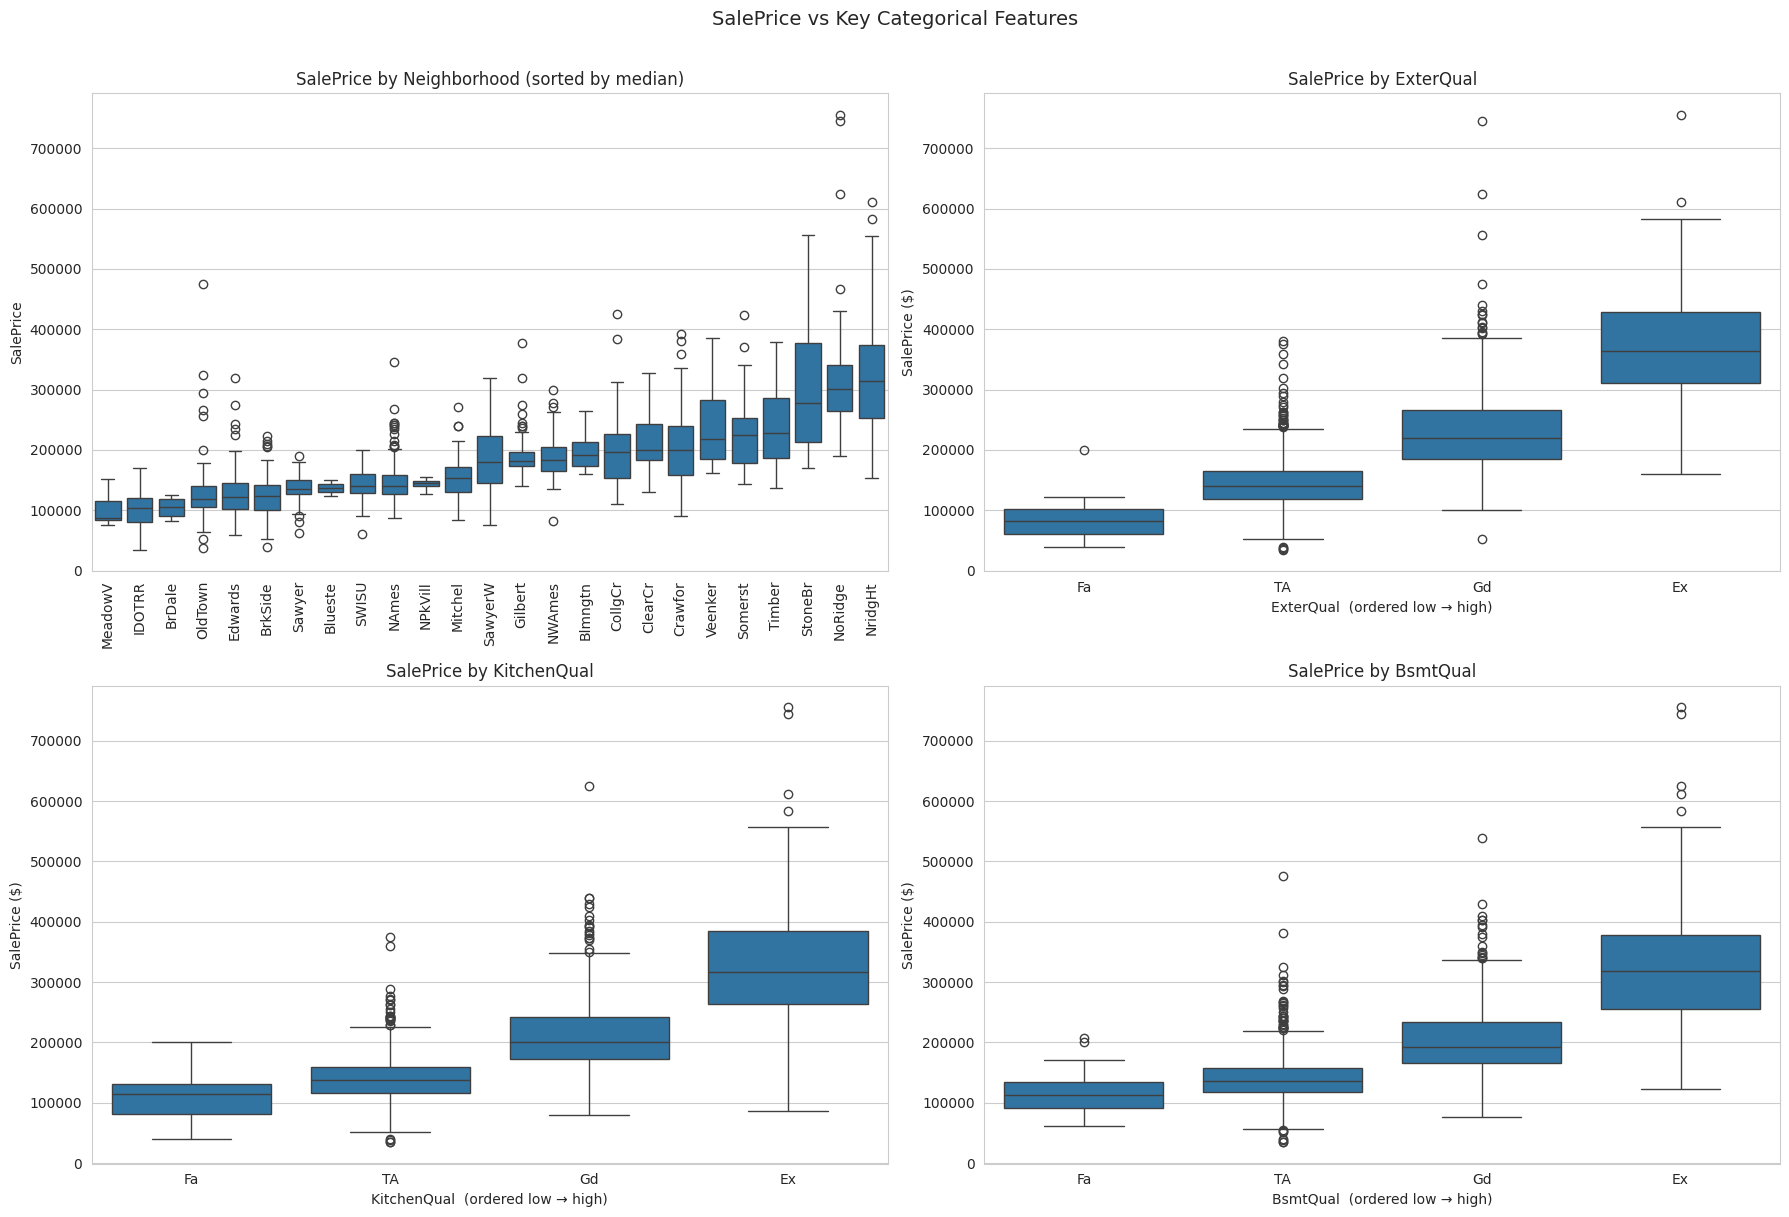

In [41]:
# Ordinal quality order from config — seaborn order= renders categories low-to-high
qual_order = EDA_CFG["quality_order"]   # ["Po", "Fa", "TA", "Gd", "Ex"]

fig, axes = plt.subplots(2, 2, figsize=(18, 12))

sns.boxplot(
    x=df["Neighborhood"], y=df[EDA_CFG["target"]], ax=axes[0, 0],
    order=df.groupby("Neighborhood")[EDA_CFG["target"]].median().sort_values().index,
)
axes[0, 0].set_title("SalePrice by Neighborhood (sorted by median)")
axes[0, 0].tick_params(axis="x", rotation=90)
axes[0, 0].set_xlabel("")

for ax, col in zip(axes.flat[1:], ["ExterQual", "KitchenQual", "BsmtQual"]):
    # Only show categories present in this dataset
    present_order = [c for c in qual_order if c in df[col].dropna().unique()]
    sns.boxplot(x=df[col], y=df[EDA_CFG["target"]], ax=ax, order=present_order)
    ax.set_title(f"SalePrice by {col}")
    ax.set_xlabel(f"{col}  (ordered low → high)")
    ax.set_ylabel("SalePrice ($)")

plt.suptitle("SalePrice vs Key Categorical Features", fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

## 6. Outlier Detection and Removal Audit

Standard IQR-based outlier detection (`< Q1 − 1.5·IQR` or `> Q3 + 1.5·IQR`) is a useful heuristic but is inappropriate as the sole removal criterion for housing data. Legitimate high-end homes — large lots, premium neighbourhoods, high `OverallQual` — produce statistically extreme values by design. Removing them would reduce model coverage and degrade holdout performance on high-value predictions.

**Removal criterion applied: domain-confirmed anomalies only.**

Two observations (indices 523 and 1298) exhibit a specific pathological pattern: `GrLivArea > 4,000 sqft` combined with `SalePrice < $200,000`. This combination is statistically inconsistent with all other comparable-footprint properties in the dataset and was flagged explicitly by the dataset author Dean De Cock (2011) as likely partial-interest sales recorded at below-market prices — a fundamentally different data-generating process from the arm's-length residential transactions the model is intended to predict.

**Impact on regression fit:** both observations are high-leverage points. Their combination of large `GrLivArea` (high-leverage position) and anomalously low `SalePrice` (large negative residual) exerts disproportionate downward pull on the regression line for large-home predictions. Including them degrades precision for the most expensive properties in the inference distribution.

All other large or expensive homes are retained. The removal decision is logged in `outlier_audit` with the original indices, triggering rule, decision, and rationale. These indices are hard-coded in `EDA_CFG["outlier_indices"]` and consumed by `02_preprocessing.ipynb` before any train/val/test split is applied.


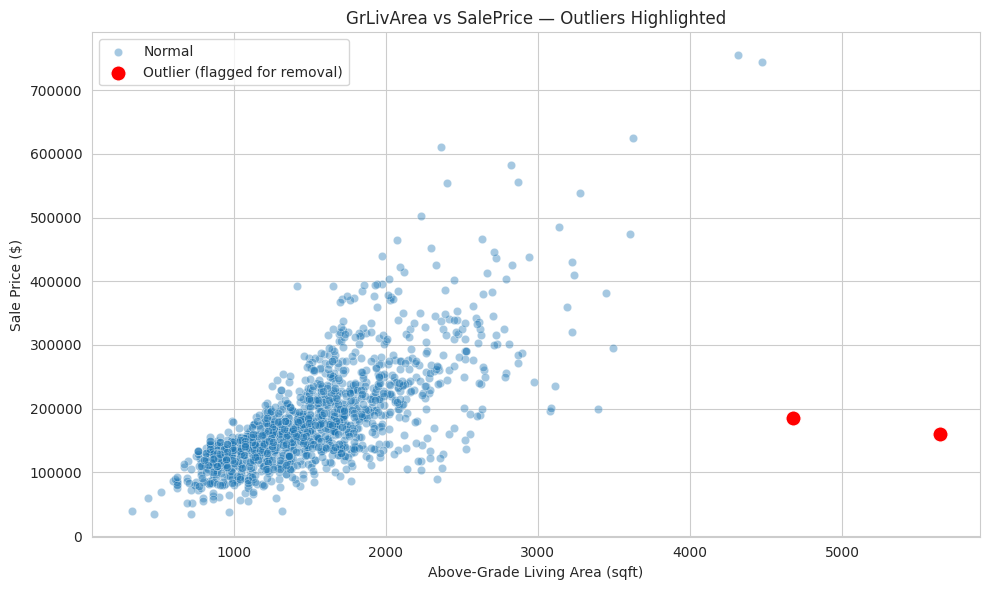

Outlier audit log — 2 record(s) flagged for removal
                GrLivArea  SalePrice                                      rule decision                                                            rationale   logged_at
original_index                                                                                                                                                          
523                  4676     184750  GrLivArea > 4000 AND SalePrice < 200,000   REMOVE  Anomalous partial sales — flagged by dataset author (De Cock, 2011)  2026-05-02
1298                 5642     160000  GrLivArea > 4000 AND SalePrice < 200,000   REMOVE  Anomalous partial sales — flagged by dataset author (De Cock, 2011)  2026-05-02


In [42]:
outlier_mask = (df["GrLivArea"] > 4000) & (df["SalePrice"] < 200_000)
normal_pts   = df[~outlier_mask]
outlier_rows = df[outlier_mask]

fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(x=normal_pts["GrLivArea"],  y=normal_pts["SalePrice"],  ax=ax, alpha=0.4, label="Normal")
sns.scatterplot(x=outlier_rows["GrLivArea"], y=outlier_rows["SalePrice"], ax=ax,
                color="red", s=120, zorder=5, label="Outlier (flagged for removal)")
ax.set_title("GrLivArea vs SalePrice — Outliers Highlighted")
ax.set_xlabel("Above-Grade Living Area (sqft)")
ax.set_ylabel("Sale Price ($)")
ax.legend()
plt.tight_layout()
plt.show()

# Structured audit trail — in production this becomes a YAML entry / database record
outlier_audit = pd.DataFrame({
    "GrLivArea": outlier_rows["GrLivArea"].values,
    "SalePrice": outlier_rows["SalePrice"].values,
    "rule":      "GrLivArea > 4000 AND SalePrice < 200,000",
    "decision":  "REMOVE",
    "rationale": "Anomalous partial sales — flagged by dataset author (De Cock, 2011)",
    "logged_at": datetime.date.today().isoformat(),
}, index=outlier_rows.index)
outlier_audit.index.name = "original_index"

print(f"Outlier audit log — {len(outlier_audit)} record(s) flagged for removal")
print(outlier_audit.to_string())

assert set(outlier_audit.index) == set(EDA_CFG["outlier_indices"]), \
    "Outlier indices mismatch vs EDA_CFG — update config!"

## 7. Feature Engineering — Empirical Validation

The following derived features are proposed on domain grounds and validated by comparing their Pearson correlation with SalePrice against the source columns they aggregate. A feature earns its place in the pipeline only if it demonstrably improves on what its raw components already provide.

| Feature | Formula | Motivation | Expected advantage |
|---------|---------|------------|-------------------|
| `TotalSF` | `TotalBsmtSF + 1stFlrSF + 2ndFlrSF` | Unified floor area signal | Stronger r than any single floor component — buyers price total livable area, not individual floors |
| `TotalBath` | `FullBath + 0.5·HalfBath + BsmtFullBath + 0.5·BsmtHalfBath` | Normalised bathroom count | Aggregates four correlated columns; half-bath weighting reflects market convention |
| `HouseAge` | `YrSold − YearBuilt` | Age at point of sale | Captures depreciation curve; non-linear with price (very old homes can appreciate as heritage) |
| `RemodAge` | `max(0, YrSold − YearRemodAdd)` | Recency of renovation | Captures value uplift from recent remodelling; clipped at 0 to handle data anomalies (rows 523/1298 have `YearRemodAdd > YrSold`) |
| `IsRemodeled` | `1 if YearRemodAdd ≠ YearBuilt` | Binary renovation flag | Complements `RemodAge`; captures the discrete value jump at renovation regardless of recency |
| `HasPool` | `1 if PoolArea > 0` | Pool presence flag | Simplifies the sparse, zero-inflated `PoolArea` distribution |
| `HasGarage` | `1 if GarageArea > 0` | Garage presence flag | More robust than the zero-filled `GarageArea` numeric |
| `HasFireplace` | `1 if Fireplaces > 0` | Fireplace presence flag | Sparse binary signal; low cardinality proxy for premium fittings |
| `TotalPorchSF` | Sum of all porch areas | Aggregated outdoor space | Reduces four individually sparse columns into one coherent measurement |

Assertions are applied after each engineered column to enforce invariants: no negative ages, no non-binary flags. These assertions replicate exactly in `02_preprocessing.ipynb`'s `add_features()` function — they are not optional debugging scaffolding.


In [46]:
df_test = df.copy()

# Derived square footage — fillna(0) guards against NaN propagation in test data
df_test["TotalSF"] = (
    df_test["TotalBsmtSF"].fillna(0)
    + df_test["1stFlrSF"].fillna(0)
    + df_test["2ndFlrSF"].fillna(0)
)
df_test["TotalBath"] = (
    df_test["FullBath"].fillna(0)    + 0.5 * df_test["HalfBath"].fillna(0)
    + df_test["BsmtFullBath"].fillna(0) + 0.5 * df_test["BsmtHalfBath"].fillna(0)
)

# Age features — clip to 0; negative values expose pre-outlier-removal data anomalies
# (row 523: YrSold=2007, YearRemodAdd=2008 — already flagged in outlier_audit)
raw_remod = df_test["YrSold"] - df_test["YearRemodAdd"]
n_negative_remod = (raw_remod < 0).sum()
if n_negative_remod > 0:
    print(f"INFO: {n_negative_remod} row(s) have negative RemodAge before outlier removal "
          f"— clipping to 0. Indices: {df_test.index[raw_remod < 0].tolist()}")

df_test["HouseAge"] = np.maximum(0, df_test["YrSold"] - df_test["YearBuilt"])
df_test["RemodAge"] = np.maximum(0, raw_remod)

# Binary presence flags
df_test["HasPool"]      = (df_test["PoolArea"]   > 0).astype(int)
df_test["HasGarage"]    = (df_test["GarageArea"] > 0).astype(int)
df_test["HasFireplace"] = (df_test["Fireplaces"] > 0).astype(int)

# Aggregated porch area
df_test["TotalPorchSF"] = (
    df_test["OpenPorchSF"].fillna(0) + df_test["EnclosedPorch"].fillna(0)
    + df_test["3SsnPorch"].fillna(0) + df_test["ScreenPorch"].fillna(0)
)

# Sanity assertions — fail fast if clipping didn't work
assert df_test["HouseAge"].min() >= 0, "Negative HouseAge after clipping"
assert df_test["RemodAge"].min() >= 0, "Negative RemodAge after clipping"
assert df_test["TotalSF"].min()  >= 0, "Negative TotalSF detected"
assert df_test[["HasPool", "HasGarage", "HasFireplace"]].isin([0, 1]).all().all(), \
    "Binary flags contain non-0/1 values"

NEW_FEATURES = [
    "TotalSF", "TotalBath", "HouseAge", "RemodAge",
    "HasPool", "HasGarage", "HasFireplace", "TotalPorchSF",
]
feature_corr = (
    df_test[NEW_FEATURES + [EDA_CFG["target"]]]
    .corr()[EDA_CFG["target"]]
    .drop(EDA_CFG["target"])
    .sort_values(ascending=False)
)
print("\nEngineered feature correlations with SalePrice:\n")
print(feature_corr.to_string())

# Quantitative comparison: do engineered features beat their raw components?
print("\n--- Engineered vs Raw ---")
comparison = {
    "TotalSF (engineered)":    feature_corr["TotalSF"],
    "1stFlrSF (raw)":          full_corr["1stFlrSF"],
    "TotalBsmtSF (raw)":       full_corr["TotalBsmtSF"],
    "TotalBath (engineered)":  feature_corr["TotalBath"],
    "FullBath (raw)":          full_corr["FullBath"],
}
for name, val in comparison.items():
    print(f"  {name:<30} r = {val:.4f}")

INFO: 1 row(s) have negative RemodAge before outlier removal — clipping to 0. Indices: [523]

Engineered feature correlations with SalePrice:

TotalSF         0.782260
TotalBath       0.631731
HasFireplace    0.471908
HasGarage       0.236832
TotalPorchSF    0.195739
HasPool         0.093708
RemodAge       -0.509096
HouseAge       -0.523350

--- Engineered vs Raw ---
  TotalSF (engineered)           r = 0.7823
  1stFlrSF (raw)                 r = 0.6059
  TotalBsmtSF (raw)              r = 0.6136
  TotalBath (engineered)         r = 0.6317
  FullBath (raw)                 r = 0.5607


## 8. EDA Decisions Log

All decisions below are encoded in `EDA_CFG` (this notebook) and mirrored in `PREP_CFG` (`02_preprocessing.ipynb`). Any modification here must be propagated to the preprocessing config — the two files form a bilateral contract for the preprocessing pipeline.

---

### Target Transformation

| Property | Value |
|----------|-------|
| Raw skewness | 1.88 (strongly right-skewed) |
| Decision | Train on `log1p(SalePrice)` |
| Rationale | Near-normal residuals; prevents high-value homes from dominating loss; required for valid prediction intervals |
| Inversion | `np.expm1(y_pred)` in `evaluate()` and FastAPI serving layer |

---

### Missing Value Strategy

| Strategy | Columns |
|----------|---------|
| `"None"` | `PoolQC`, `MiscFeature`, `Alley`, `Fence`, `FireplaceQu`, `GarageType/Finish/Qual/Cond`, `BsmtQual/Cond/Exposure/FinType1/FinType2`, `MasVnrType` |
| `0` | `MasVnrArea`, `GarageYrBlt`, `GarageArea`, `GarageCars`, `BsmtFinSF1/SF2/UnfSF`, `TotalBsmtSF` |
| Mode | `Electrical`, `MSZoning`, `Exterior1st`, `Exterior2nd`, `SaleType` |
| Neighbourhood-group median | `LotFrontage` |

---

### Top Predictive Features

**Numeric** (by `|r|` with SalePrice): `OverallQual` (0.791), `GrLivArea` (0.709), `GarageCars` (0.640), `TotalBsmtSF` (0.614), `1stFlrSF` (0.606)

**Categorical**: `Neighborhood` (largest median price spread), `ExterQual`, `KitchenQual`, `BsmtQual`

---

### Columns Dropped

| Column | Reason |
|--------|--------|
| `Id` | Row identifier; no predictive signal |
| `Utilities` | Near-zero variance (>99% "AllPub") |

---

### Outliers Removed

| Index | Rule | Source |
|-------|------|--------|
| 523 | `GrLivArea > 4,000 AND SalePrice < $200,000` | De Cock (2011) — partial sale |
| 1298 | `GrLivArea > 4,000 AND SalePrice < $200,000` | De Cock (2011) — partial sale |

---

### Engineered Features

`TotalSF`, `TotalBath`, `HouseAge`, `RemodAge`, `IsRemodeled`, `HasPool`, `HasGarage`, `HasFireplace`, `TotalPorchSF`

---

### Multicollinearity Pairs (noted for model interpretation)

| Pair | r |
|------|---|
| `GarageCars` / `GarageArea` | 0.88 |
| `TotalBsmtSF` / `1stFlrSF` | 0.82 |
| `GrLivArea` / `TotRmsAbvGrd` | 0.83 |

---

**→ Next**: `02_preprocessing.ipynb` — full sklearn `ColumnTransformer` pipeline implementing every decision above.
